# Auswirkungen der COVID-19-Pandemie auf verschiedene Marktsektoren (2018–2023)

## Projektübersicht

Dieses Notebook dokumentiert die vollständige Datenaufbereitung sowie die explorative Datenanalyse (EDA) und bildet die Grundlage für die nachfolgenden Analysen in SQL und Power BI.

Hierfür werden historische Börsendaten aus Yahoo Finance für vier Marktsektoren – Technologie, Pharma, Reise & Tourismus sowie Entertainment – analysiert. Zunächst werden die Daten bereinigt und für ein Star Schema vorbereitet, das anschließend in SQL und Power BI verwendet wird. Darauf aufbauend wird eine explorative Datenanalyse durchgeführt, um die Entwicklung der einzelnen Sektoren und Unternehmen im Zeitraum 2018 bis 2023 zu untersuchen.

Ziel des Notebooks ist es, erste Zusammenhänge, Unterschiede und Entwicklungen zwischen den Sektoren zu identifizieren und damit die Grundlage für die nachfolgenden Analysen in SQL und Power BI zu schaffen.

In [688]:
import pandas as pd 

# yfinance is used to download historical stock market data from Yahoo Finance.
# Further reading: https://github.com/ranaroussi/yfinance
import yfinance as yf

In [689]:
# Create a dictionary that maps each Technology company to its Yahoo Finance ticker symbol.
technology = {
    "Microsoft": "MSFT",
    "NVIDIA": "NVDA",
    "Adobe": "ADBE",
    "Salesforce": "CRM",
    "Cisco": "CSCO",
    "Technology Select Sector SPDR ETF": "XLK"
}   

In [690]:
health = {
    "Pfizer": "PFE",
    "AbbVie": "ABBV",
    "Abbott Laboratories": "ABT",
    "Johnson & Johnson": "JNJ",
    "Eli Lilly": "LLY",
    "Health Care Select Sector SPDR ETF": "XLV"
}

In [691]:
travel = { 
    "Booking Holdings": "BKNG",
    "Expedia": "EXPE",
    "Marriot": "MAR",
    "Delta Air Lines": "DAL",
    "Carnival": "CCL",
    "U.S. Global Jets ETF": "JETS"
}    

In [692]:
entertainment = { 
    "Netflix": "NFLX",
    "Disney": "DIS",
    "Warner Bros. Discovery": "WBD",
    "Take-Two Interactive": "TTWO",
    "Electronic Arts": "EA",
    "Comcast": "CMCSA"
}    

In [693]:
# Combine all sectors into a single DataFrame containing the sector, company name, and ticker symbol.
assets = {
    "Technologie": technology,
    "Pharma": health,
    "Reise": travel,
    "Entertainment": entertainment
}    

In [694]:
rows = []

In [695]:
for sector, companies in assets.items():
    for company, ticker in companies.items():
        rows.append([sector, company, ticker])

In [696]:
df_assets = pd.DataFrame(
    rows,
    columns=["Sector", "Company", "Ticker"]
)    

In [697]:
df_assets

,Sector,Company,Ticker
0,Technologie,Microsoft,MSFT
1,Technologie,NVIDIA,NVDA
2,Technologie,Adobe,ADBE
3,Technologie,Salesforce,CRM
4,Technologie,Cisco,CSCO
5,Technologie,Technology Select Sector SPDR ETF,XLK
6,Pharma,Pfizer,PFE
7,Pharma,AbbVie,ABBV
8,Pharma,Abbott Laboratories,ABT
9,Pharma,Johnson & Johnson,JNJ


In [698]:
# Download sample stock market data for Microsoft to inspect the dataset structure.
test_data = yf.download(
    "MSFT",
    start="2018-01-01",
    end="2024-01-01"
)    

[*********************100%***********************]  1 of 1 completed


In [699]:
test_data.head()

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2018-01-02,78.699913,79.029547,78.287874,78.864730,22483800
2018-01-03,79.066162,79.212669,78.718219,78.800623,26061400
2018-01-04,79.762054,80.265663,79.267604,79.285914,21912000
2018-01-05,80.750969,80.952413,80.055075,80.265677,23407100
2018-01-08,80.833366,81.108063,80.210726,80.760113,22113000


In [700]:
# Create a list of all ticker symbols from the asset DataFrame.
# Further reading: https://www.geeksforgeeks.org/python/python-pandas-series-tolist/
ticker_list = df_assets["Ticker"].tolist()

In [701]:
ticker_list

['MSFT',
 'NVDA',
 'ADBE',
 'CRM',
 'CSCO',
 'XLK',
 'PFE',
 'ABBV',
 'ABT',
 'JNJ',
 'LLY',
 'XLV',
 'BKNG',
 'EXPE',
 'MAR',
 'DAL',
 'CCL',
 'JETS',
 'NFLX',
 'DIS',
 'WBD',
 'TTWO',
 'EA',
 'CMCSA']

In [702]:
# Download historical stock market data for all selected companies and ETFs.
all_data = yf.download(
    ticker_list,
    start="2018-01-01",
    end="2024-01-01"
)    

[*********************100%***********************]  24 of 24 completed


In [703]:
all_data

Price            Close                                                 \
Ticker            ABBV         ABT        ADBE        BKNG        CCL   
Date                                                                    
2018-01-02   68.287094   50.148399  177.699997   69.905067  60.785404   
2018-01-03   69.355705   50.259285  181.039993   71.448677  60.922001   
2018-01-04   68.960167   50.173992  183.220001   70.786346  60.876453   
2018-01-05   70.160637   50.319008  185.339996   71.424393  60.375607   
2018-01-08   69.036499   50.173992  185.039993   72.531670  60.147949   
...                ...         ...         ...         ...        ...   
2023-12-22  141.090103  102.994812  598.750000  138.486267  18.728189   
2023-12-26  140.798721  103.183746  598.260010  139.698502  18.411602   
2023-12-27  141.035477  103.712753  596.080017  138.444748  18.342348   
2023-12-28  140.917114  104.288979  595.520020  139.064774  18.470961   
2023-12-29  141.117416  103.977249  596.599976  138.937454  18.342348   

Price                                                                ...  \
Ticker          CMCSA         CRM       CSCO        DAL         DIS  ...   
Date                                                                 ...   
2018-01-02  30.406317  102.634369  30.156723  51.660381  105.416771  ...   
2018-01-03  29.917671  103.499405  30.397293  50.704376  105.869354  ...   
2018-01-04  30.110163  104.865784  30.483292  50.704376  105.822235  ...   
2018-01-05  30.384100  106.261612  30.905472  50.959316  105.247055  ...   
2018-01-08  29.969500  107.008698  31.226015  49.784794  103.738396  ...   
...               ...         ...        ...        ...         ...  ...   
2023-12-22  37.184532  261.810547  46.611794  39.895580   88.537254  ...   
2023-12-26  37.125378  261.692566  46.788597  39.536690   88.469154  ...   
2023-12-27  37.176098  262.184082  46.937489  39.371788   87.914703  ...   
2023-12-28  37.285946  261.063446  46.974709  39.410591   87.934174  ...   
2023-12-29  37.057774  258.665009  47.011932  39.022583   87.827164  ...   

Price        Volume                                                     \
Ticker          LLY      MAR      MSFT       NFLX       NVDA       PFE   
Date                                                                     
2018-01-02  3456700  2949200  22483800  109669000  355616000  17059833   
2018-01-03  3078400  1507900  26061400   85914000  914704000  14183151   
2018-01-04  2462500  3187000  21912000   60296000  583268000  13046517   
2018-01-05  2946300  3404400  23407100   70332000  580124000  13167517   
2018-01-08  3251400  3275500  22113000   55802000  881216000  19964341   
...             ...      ...       ...        ...        ...       ...   
2023-12-22  2226100   995000  17107500   27027000  252507000  35162300   
2023-12-26  1678700  1118600  12673100   20345000  244200000  30119100   
2023-12-27  2163400  1329600  14905400   25613000  233648000  35000700   
2023-12-28  1973500   971000  14327000   17105000  246587000  30472900   
2023-12-29  2000100  2008700  18730800   27406000  389293000  30363100   

Price                                             
Ticker         TTWO       WBD       XLK      XLV  
Date                                              
2018-01-02  1569300   5028200  27445600  6708900  
2018-01-03  1451500   5292900  22663600  7606500  
2018-01-04  1319300   7875900  21493200  7762500  
2018-01-05  1513600   8498800  19356000  7579300  
2018-01-08  1591400   4103800  13467800  5167300  
...             ...       ...       ...      ...  
2023-12-22  1347600  21560800  10215000  5355100  
2023-12-26   763300  17934500   6207600  3688600  
2023-12-27   936900  20714200  11764600  5444100  
2023-12-28   784900  16578600   9615400  5800200  
2023-12-29   916600  20267500  12190600  5590000  

[1509 rows x 120 columns]

In [704]:
# Check the dataset for missing values.
all_data.isna().sum().sum()

np.int64(0)

In [705]:
# Convert the dataset from wide format to long format for easier analysis.
# Further reading: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.stack.html
df_long = all_data.stack(level="Ticker", future_stack=True).reset_index()

In [706]:
df_long.head()

Price,Date,Ticker,Close,High,Low,Open,Volume
0,2018-01-02,ABBV,68.287094,68.627106,67.135211,67.405833,4561300
1,2018-01-02,ABT,50.148399,50.498133,49.320980,49.645124,10112800
2,2018-01-02,ADBE,177.699997,177.800003,175.259995,175.850006,2432800
3,2018-01-02,BKNG,69.905067,70.136555,68.328555,68.547507,11887500
4,2018-01-02,CCL,60.785404,61.249834,60.648806,61.213407,2783800


In [707]:
# << Prepare the dataset as a star schema for use in SQL databases and Power BI.>>

# Reset the index to create consecutive AssetIDs for each company.
df_assets = df_assets.reset_index(drop=True)

In [708]:
df_assets["AssetID"] = df_assets.index + 1

In [709]:
df_assets

,Sector,Company,Ticker,AssetID
0,Technologie,Microsoft,MSFT,1
1,Technologie,NVIDIA,NVDA,2
2,Technologie,Adobe,ADBE,3
3,Technologie,Salesforce,CRM,4
4,Technologie,Cisco,CSCO,5
5,Technologie,Technology Select Sector SPDR ETF,XLK,6
6,Pharma,Pfizer,PFE,7
7,Pharma,AbbVie,ABBV,8
8,Pharma,Abbott Laboratories,ABT,9
9,Pharma,Johnson & Johnson,JNJ,10


In [710]:
# Create the fact table by linking the price data with the AssetID.
# Further reading: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html
df_prices = df_long.merge(
    df_assets[["AssetID", "Ticker"]],
    on="Ticker",
    how="left"
)    

In [711]:
df_prices.head()

,Date,Ticker,Close,High,Low,Open,Volume,AssetID
0,2018-01-02,ABBV,68.287094,68.627106,67.135211,67.405833,4561300,8
1,2018-01-02,ABT,50.148399,50.498133,49.320980,49.645124,10112800,9
2,2018-01-02,ADBE,177.699997,177.800003,175.259995,175.850006,2432800,3
3,2018-01-02,BKNG,69.905067,70.136555,68.328555,68.547507,11887500,13
4,2018-01-02,CCL,60.785404,61.249834,60.648806,61.213407,2783800,17


In [712]:
# Verify that all records have a valid AssetID after the merge.
df_prices["AssetID"].isna().sum()

np.int64(0)

In [713]:
# Remove the Ticker column, as it is no longer needed after assigning the AssetID.
fact_prices= df_prices.drop(columns=["Ticker"])

In [714]:
fact_prices.head()

,Date,Close,High,Low,Open,Volume,AssetID
0,2018-01-02,68.287094,68.627106,67.135211,67.405833,4561300,8
1,2018-01-02,50.148399,50.498133,49.320980,49.645124,10112800,9
2,2018-01-02,177.699997,177.800003,175.259995,175.850006,2432800,3
3,2018-01-02,69.905067,70.136555,68.328555,68.547507,11887500,13
4,2018-01-02,60.785404,61.249834,60.648806,61.213407,2783800,17


In [715]:
# Create the date dimension table for the star schema used in SQL databases and Power BI.
# Further reading: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html
dim_date = pd.DataFrame({
    "Date": fact_prices["Date"].drop_duplicates().sort_values()
})    

In [716]:
# Add date attributes to support time-based analysis.
#
# Further reading: 
# https://pandas.pydata.org/docs/reference/series.html#datetimelike-properties
# https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.isocalendar.html
dim_date["DateID"] = ...
dim_date["DateID"] = range(1, len(dim_data) + 1)

dim_date["Year"] = dim_data["Date"].dt.year
dim_date["Quarter"] = dim_date["Date"].dt.quarter
dim_date["Month"] = dim_date["Date"].dt.month
dim_date["MonthName"] = dim_date["Date"].dt.month_name()
dim_date["Week"] = dim_date["Date"].dt.isocalendar().week
dim_date["Weekday"] = dim_data["Date"].dt.weekday + 1
dim_date["weekdayName"] = dim_date["Date"].dt.day_name()

In [717]:
dim_date.head()

,Date,DateID,Year,Quarter,Month,MonthName,Week,Weekday,weekdayName
0,2018-01-02,1,2018,1,1,January,1,2,Tuesday
24,2018-01-03,2,2018,1,1,January,1,3,Wednesday
48,2018-01-04,3,2018,1,1,January,1,4,Thursday
72,2018-01-05,4,2018,1,1,January,1,5,Friday
96,2018-01-08,5,2018,1,1,January,2,1,Monday


In [718]:
# Link the DateID to the fact table for the star schema.
fact_prices = fact_prices.merge(
    dim_date[["Date", "DateID"]],
    on="Date",
    how="left"
)    

In [719]:
fact_prices.head()

,Date,Close,High,Low,Open,Volume,AssetID,DateID
0,2018-01-02,68.287094,68.627106,67.135211,67.405833,4561300,8,1
1,2018-01-02,50.148399,50.498133,49.320980,49.645124,10112800,9,1
2,2018-01-02,177.699997,177.800003,175.259995,175.850006,2432800,3,1
3,2018-01-02,69.905067,70.136555,68.328555,68.547507,11887500,13,1
4,2018-01-02,60.785404,61.249834,60.648806,61.213407,2783800,17,1


In [720]:
# Remove the Date column because DateID is used as the foreign key.
fact_prices = fact_prices.drop(columns=["Date"])

In [721]:
fact_prices.head()

,Close,High,Low,Open,Volume,AssetID,DateID
0,68.287094,68.627106,67.135211,67.405833,4561300,8,1
1,50.148399,50.498133,49.320980,49.645124,10112800,9,1
2,177.699997,177.800003,175.259995,175.850006,2432800,3,1
3,69.905067,70.136555,68.328555,68.547507,11887500,13,1
4,60.785404,61.249834,60.648806,61.213407,2783800,17,1


In [722]:
# Store the currency in the asset table to avoid repeating the same information in other tables.
df_assets["Currency"] = "USD"

In [723]:
df_assets

,Sector,Company,Ticker,AssetID,Currency
0,Technologie,Microsoft,MSFT,1,USD
1,Technologie,NVIDIA,NVDA,2,USD
2,Technologie,Adobe,ADBE,3,USD
3,Technologie,Salesforce,CRM,4,USD
4,Technologie,Cisco,CSCO,5,USD
5,Technologie,Technology Select Sector SPDR ETF,XLK,6,USD
6,Pharma,Pfizer,PFE,7,USD
7,Pharma,AbbVie,ABBV,8,USD
8,Pharma,Abbott Laboratories,ABT,9,USD
9,Pharma,Johnson & Johnson,JNJ,10,USD


In [724]:
# Rename the asset table to match the star schema naming convention.
dim_assets = df_assets

In [725]:
# Export the star schema tables as CSV files for SQL and Power BI.
dim_assets.to_csv("dim_assets.csv", index=False)
dim_date.to_csv("dim_date.csv", index=False)
fact_prices.to_csv("fact_prices.csv", index=False)

In [726]:
fact_prices.shape

(36216, 7)

In [727]:
# Create a dataset for exploratory data analysis (EDA) by combining price, company, and sector information.
eda_data = fact_prices.merge(
    dim_assets[["AssetID", "Company", "Sector"]],
    on="AssetID",
    how="left"
)    

In [728]:
eda_data.head()

,Close,High,Low,Open,Volume,AssetID,DateID,Company,Sector
0,68.287094,68.627106,67.135211,67.405833,4561300,8,1,AbbVie,Pharma
1,50.148399,50.498133,49.320980,49.645124,10112800,9,1,Abbott Laboratories,Pharma
2,177.699997,177.800003,175.259995,175.850006,2432800,3,1,Adobe,Technologie
3,69.905067,70.136555,68.328555,68.547507,11887500,13,1,Booking Holdings,Reise
4,60.785404,61.249834,60.648806,61.213407,2783800,17,1,Carnival,Reise


In [729]:
# Complete the EDA dataset by adding the date information.
eda_data = eda_data.merge(
    dim_date[["DateID", "Date"]],
    on="DateID",
    how="left"
)    

In [730]:
eda_data.head()

,Close,High,Low,Open,Volume,AssetID,DateID,Company,Sector,Date
0,68.287094,68.627106,67.135211,67.405833,4561300,8,1,AbbVie,Pharma,2018-01-02
1,50.148399,50.498133,49.320980,49.645124,10112800,9,1,Abbott Laboratories,Pharma,2018-01-02
2,177.699997,177.800003,175.259995,175.850006,2432800,3,1,Adobe,Technologie,2018-01-02
3,69.905067,70.136555,68.328555,68.547507,11887500,13,1,Booking Holdings,Reise,2018-01-02
4,60.785404,61.249834,60.648806,61.213407,2783800,17,1,Carnival,Reise,2018-01-02


In [731]:
eda_data.describe()

,Close,High,Low,Open,Volume,AssetID,DateID,Date
count,36216.000000,36216.000000,36216.000000,36216.000000,3.621600e+04,36216.000000,36216.000000,36216
mean,102.362983,103.551059,101.114082,102.355515,3.383323e+07,12.500000,755.000000,2020-12-30 14:13:07
min,3.146729,3.218538,3.081853,3.132120,1.000000e+03,1.000000,1.000000,2018-01-02 00:00:00
25%,35.207309,35.627608,34.729400,35.206299,3.568850e+06,6.750000,378.000000,2019-07-03 00:00:00
50%,83.241219,84.275225,82.262145,83.228500,7.634900e+06,12.500000,755.000000,2020-12-30 00:00:00
75%,129.085991,130.360801,127.635560,128.985364,2.009570e+07,18.250000,1132.000000,2022-06-30 00:00:00
max,688.369995,699.539978,678.909973,696.280029,2.511528e+09,24.000000,1509.000000,2023-12-29 00:00:00
std,95.289932,96.372678,94.109692,95.268426,1.047718e+08,6.922282,435.616697,NaN


**Hinweis:** Die zusammenfassenden Statistiken sollten mit Vorsicht interpretiert werden, da der Datensatz mehrere Unternehmen und ETFs mit unterschiedlichen Kursniveaus enthält. Sie liefern daher nur einen allgemeinen Überblick und eignen sich nicht für aussagekräftige Vergleiche zwischen den einzelnen Assets.

In [732]:
# Display the companies included in each sector.
eda_data.groupby("Sector")["Company"].unique()

Sector
Entertainment    [Comcast, Disney, Electronic Arts, Netflix, Ta...
Pharma           [AbbVie, Abbott Laboratories, Johnson & Johnso...
Reise            [Booking Holdings, Carnival, Delta Air Lines, ...
Technologie      [Adobe, Salesforce, Cisco, Microsoft, NVIDIA, ...
Name: Company, dtype: object

In [733]:
# Print the companies in each sector in a readable format.
for sector, companies in eda_data.groupby("Sector")["Company"].unique().items():
    print(f"\n{sector}")
    for company in companies:
        print(f" - {company}")


Entertainment
 - Comcast
 - Disney
 - Electronic Arts
 - Netflix
 - Take-Two Interactive
 - Warner Bros. Discovery

Pharma
 - AbbVie
 - Abbott Laboratories
 - Johnson & Johnson
 - Eli Lilly
 - Pfizer
 - Health Care Select Sector SPDR ETF

Reise
 - Booking Holdings
 - Carnival
 - Delta Air Lines
 - Expedia
 - U.S. Global Jets ETF
 - Marriot

Technologie
 - Adobe
 - Salesforce
 - Cisco
 - Microsoft
 - NVIDIA
 - Technology Select Sector SPDR ETF


In [734]:
# Calculate the average closing price for each sector over time.
sector_close = (
    eda_data
    .groupby(["Date", "Sector"])["Close"]
    .mean()
    .reset_index()
)

In [735]:
sector_close.head()

,Date,Sector,Close
0,2018-01-02,Entertainment,66.356105
1,2018-01-02,Pharma,66.484743
2,2018-01-02,Reise,75.977623
3,2018-01-02,Technologie,70.658480
4,2018-01-03,Entertainment,66.549948


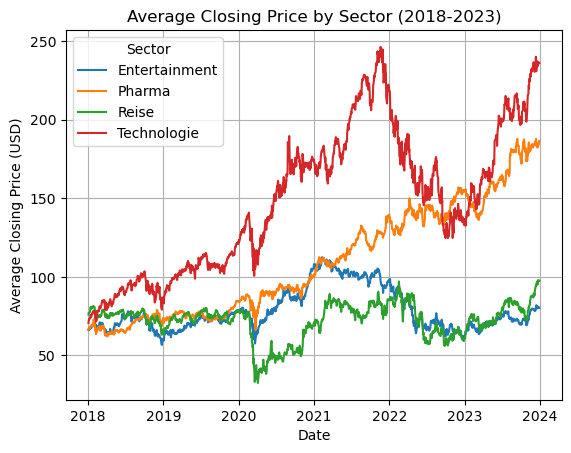

In [736]:
# Plot the average closing price for each sector.
# Further reading: https://matplotlib.org/stable/tutorials/index.html
import matplotlib.pylab as plt

for sector in sector_close["Sector"].unique():
    data = sector_close[sector_close["Sector"] == sector]
    plt.plot(data["Date"], data["Close"], label=sector)

plt.title("Average Closing Price by Sector (2018-2023)")
plt.xlabel("Date")
plt.ylabel("Average Closing Price (USD)")
plt.legend(title="Sector")
plt.grid(True)

plt.show()  

**Hinweis:** Dieses Diagramm sollte mit Vorsicht interpretiert werden, da die Unternehmen in den einzelnen Sektoren sehr unterschiedliche Aktienkurse haben. Ein höherer durchschnittlicher Kurs bedeutet daher nicht automatisch eine bessere Entwicklung oder Performance eines Sektors.

In [737]:
# Convert the data to a wide format to simplify sector comparison and index calculation.
sector_pivot = sector_close.pivot(
    index="Date",
    columns="Sector",
    values="Close"
)

sector_pivot.head()

Sector,Entertainment,Pharma,Reise,Technologie
Date,,,,
2018-01-02,66.356105,66.484743,75.977623,70.658480
2018-01-03,66.549948,67.068393,77.055185,71.555929
2018-01-04,66.111448,67.068708,76.984265,72.307265
2018-01-05,67.434977,67.711959,77.009789,73.188869
2018-01-08,67.421346,67.371354,77.394993,73.376905


In [738]:
# Normalize all sectors to an index starting at 100 for easier performance comparison.
sector_index = sector_pivot.div(sector_pivot.iloc[0]).mul(100)

sector_index.head()                                                              

Sector,Entertainment,Pharma,Reise,Technologie
Date,,,,
2018-01-02,100.000000,100.000000,100.000000,100.000000
2018-01-03,100.292126,100.877871,101.418261,101.270122
2018-01-04,99.631296,100.878344,101.324919,102.333457
2018-01-05,101.625882,101.845860,101.358512,103.581155
2018-01-08,101.605339,101.333555,101.865509,103.847274


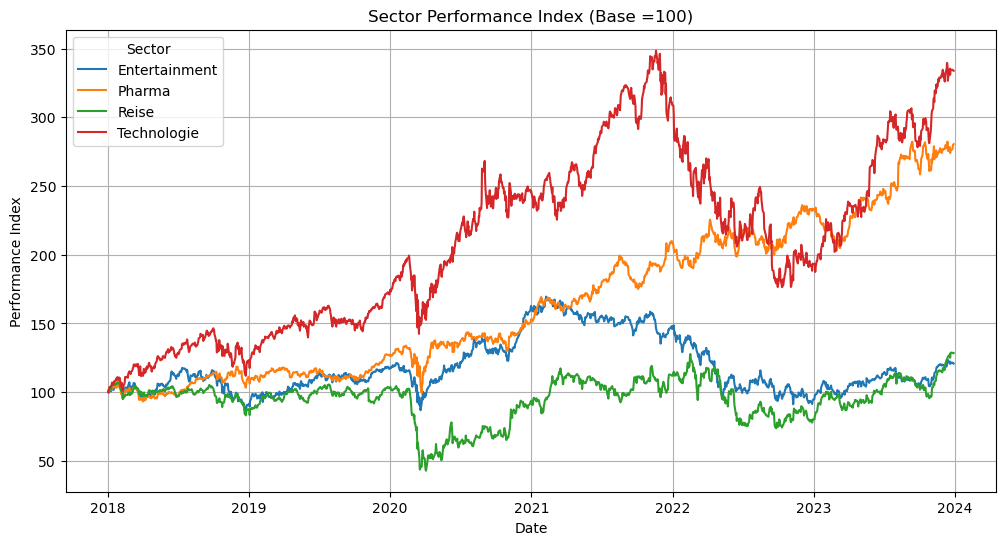

In [739]:
# Plot the normalized sector performance (Base = 100) over time.
import matplotlib.pylab as plt

plt.figure(figsize=(12, 6))

for sector in sector_index.columns:
    plt.plot(
        sector_index.index,
        sector_index[sector],
        label=sector
    )

plt.title("Sector Performance Index (Base =100)")
plt.xlabel("Date")
plt.ylabel("Performance Index")
plt.legend(title="Sector")
plt.grid(True)

plt.show()

**Interpretation:** Dieses Diagramm zeigt die Entwicklung der Sektoren auf Basis eines gemeinsamen Startwerts von 100. Dadurch lässt sich die relative Performance der Sektoren besser vergleichen als mit den absoluten Aktienkursen. Es wird deutlich, dass der Technologiesektor im gesamten Zeitraum die stärkste Entwicklung zeigt, während der Reisesektor während der COVID-19-Pandemie den stärksten Einbruch verzeichnet. Pharma entwickelt sich kontinuierlich positiv, während Entertainment insgesamt eine schwächere Entwicklung zeigt.

In [740]:
# Compare the last closing price with the first closing price of each sector
# to calculate the total return (%) over the entire analysis period.
#
# Further reading:
# https://www.investopedia.com/terms/r/return.asp
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html
sector_return = (
    (sector_pivot.iloc[-1] / sector_pivot.iloc[0] -1) * 100
).round(2)

sector_return

Sector
Entertainment     20.84
Pharma           180.43
Reise             28.41
Technologie      233.85
dtype: float64

**Erklärung:** Zur Berechnung der Gesamtrendite wird der erste und der letzte Wert jedes Sektors verwendet. Dabei greift iloc[0] auf die erste Zeile (Beginn des Betrachtungszeitraums) und iloc[-1] auf die letzte Zeile (Ende des Betrachtungszeitraums) zu. Anschließend wird die Formel (Endwert/Anfangswert−1)×100 angewendet. Dadurch wird die prozentuale Veränderung zwischen dem ersten und letzten Wert berechnet und die Gesamtrendite des jeweiligen Sektors ermittelt.

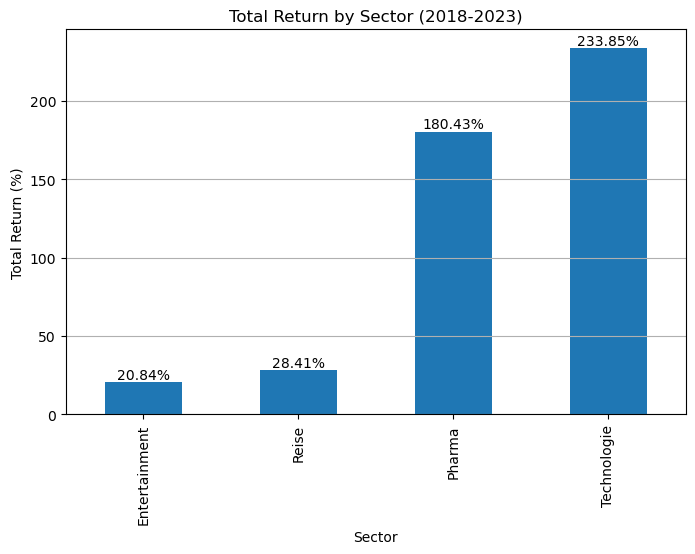

In [741]:
# Plot the total return of each sector as a bar chart.
plt.figure(figsize=(8, 5))

# Sort sectors by total return before plotting.
ax = sector_return.sort_values().plot(kind="bar")

plt.title("Total Return by Sector (2018-2023)")
plt.xlabel("Sector")
plt.ylabel("Total Return (%)")
plt.grid(axis="y")

# Display the total return (%) on top of each bar.
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )   
    
plt.show()

**Interpretation:** Der Technologiesektor erzielte im Zeitraum 2018–2023 mit rund 234 % die höchste Gesamtrendite, gefolgt vom Pharmasektor mit etwa 180 %. Die Sektoren Reise (28 %) und Entertainment (21 %) entwickelten sich im Vergleich deutlich schwächer. Das Diagramm verdeutlicht die unterschiedlichen langfristigen Entwicklungen der vier betrachteten Sektoren.

In [742]:
# Calculate the total return (%) for each company over the entire analysis period.
# Total return formula: ((final closing price / initial closing price) - 1) × 100.
#
# Further reading:
# https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.core.groupby.DataFrameGroupBy.apply.html
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html
company_return = (
    eda_data.groupby("Company")
    .apply(lambda x: (x["Close"].iloc[-1] / x["Close"].iloc[0] - 1) * 100)
    .sort_values(ascending=False)
)

company_return

Company
NVIDIA                                904.242406
Eli Lilly                             664.920522
Microsoft                             368.708212
Adobe                                 235.734376
Technology Select Sector SPDR ETF     217.594471
Salesforce                            152.025721
Netflix                               142.144521
Abbott Laboratories                   107.339118
AbbVie                                106.653129
Booking Holdings                       98.751620
Health Care Select Sector SPDR ETF     80.667640
Marriot                                76.703936
Cisco                                  55.892045
Take-Two Interactive                   42.585047
Johnson & Johnson                      32.387530
Expedia                                28.247521
Electronic Arts                        27.283428
Comcast                                21.875247
Pfizer                                  4.421276
Disney                                -16.685777
Delta Air Li

In [743]:
# Select the five companies with the highest total return.
top5 = company_return.head(5)

In [744]:
# Select the five companies with the lowest total return.
bottom5 = company_return.tail(5)

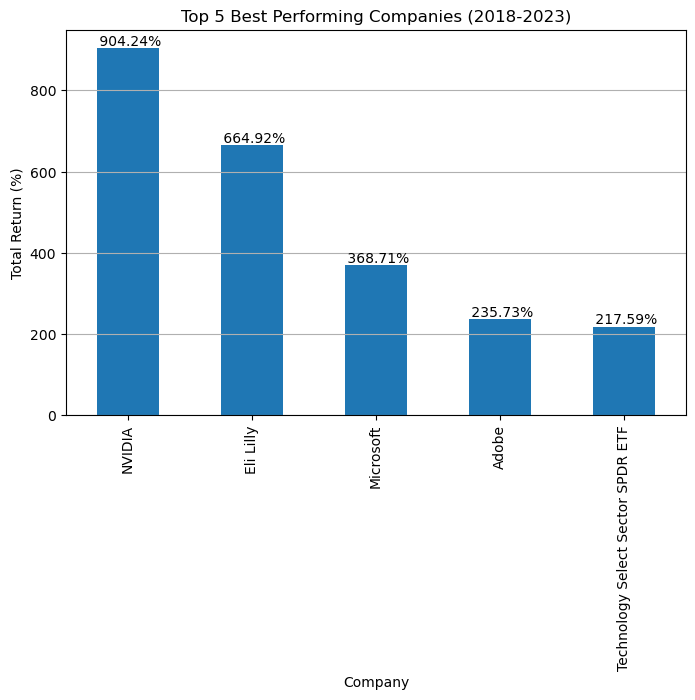

In [745]:
# Plot the five companies with the highest total return.
plt.figure(figsize=(8, 5))

ax = top5.plot(kind="bar")

plt.title("Top 5 Best Performing Companies (2018-2023)")
plt.xlabel("Company")
plt.ylabel("Total Return (%)")
plt.grid(axis="y")

# Display the return percentage above each bar.
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
       bar.get_x() + bar.get_width()/2,
       height,
       f"{height: .2f}%",
       ha="center",
       va="bottom"
    )

plt.show()

**Interpretation:** Die Grafik zeigt die fünf Unternehmen mit der höchsten Gesamtrendite im Zeitraum 2018–2023. NVIDIA erzielte mit Abstand die höchste Rendite, gefolgt von Eli Lilly und Microsoft. Die Entwicklung wurde nicht nur durch die Corona-Pandemie beeinflusst, sondern auch durch weitere Faktoren wie den KI-Boom, Inflation, Zinserhöhungen und geopolitische Ereignisse.

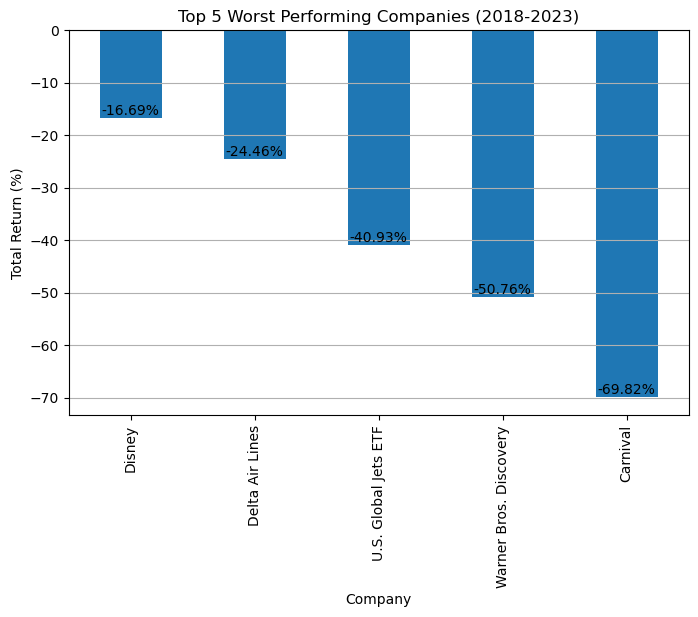

In [746]:
# Plot the five companies with the lowest total return.
plt.figure(figsize=(8, 5))

ax = bottom5.plot(kind="bar")

plt.title("Top 5 Worst Performing Companies (2018-2023)")
plt.xlabel("Company")
plt.ylabel("Total Return (%)")
plt.grid(axis="y")

# Display the return percentage above each bar.
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
       bar.get_x() + bar.get_width()/2,
       height,
       f"{height: .2f}%",
       ha="center",
       va="bottom"
    )

plt.show()

**Interpretation:** Die Grafik zeigt die fünf Unternehmen mit der niedrigsten Gesamtrendite im Zeitraum 2018–2023. Besonders Disney und Warner Bros. Discovery verzeichneten deutliche Verluste. Die Entwicklung wurde nicht nur durch die Corona-Pandemie, sondern auch durch Veränderungen im Streaming-Markt, steigende Kosten und weitere wirtschaftliche Faktoren beeinflusst.

In [747]:
# Classify each observation into Pre-COVID, COVID, or Post-COVID based on the date.
# Further reading: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html
eda_data["Period"] = "Post-COVID"

eda_data.loc[eda_data["Date"] < "2020-01-01", "Period"] = "Pre-COVID"

eda_data.loc[
    (eda_data["Date"] >= "2020-01-01") &
    (eda_data["Date"] < "2022-01-01"), 
    "Period"
    ] = "COVID"    

In [748]:
eda_data[["Date", "Period"]].head(10)

,Date,Period
0,2018-01-02,Pre-COVID
1,2018-01-02,Pre-COVID
2,2018-01-02,Pre-COVID
3,2018-01-02,Pre-COVID
4,2018-01-02,Pre-COVID
5,2018-01-02,Pre-COVID
6,2018-01-02,Pre-COVID
7,2018-01-02,Pre-COVID
8,2018-01-02,Pre-COVID
9,2018-01-02,Pre-COVID


In [749]:
# Verify that observations are assigned correctly to each period.
eda_data["Period"].value_counts()

Period
COVID         12120
Pre-COVID     12072
Post-COVID    12024
Name: count, dtype: int64

In [750]:
# Calculate the average closing price for each sector in each period.
period_sector = (
    eda_data
    .groupby(["Period", "Sector"])["Close"] 
    .mean()
    .reset_index()
)

period_sector

,Period,Sector,Close
0,COVID,Entertainment,92.066745
1,COVID,Pharma,104.010044
2,COVID,Reise,67.644671
3,COVID,Technologie,174.830958
4,Post-COVID,Entertainment,73.134044
5,Post-COVID,Pharma,152.551160
6,Post-COVID,Reise,74.684983
7,Post-COVID,Technologie,174.526630
8,Pre-COVID,Entertainment,70.241174
9,Pre-COVID,Pharma,72.595860


**Hinweis:** Die Tabelle zeigt die durchschnittlichen Schlusskurse der einzelnen Sektoren in den drei Zeiträumen (Pre-COVID, COVID und Post-COVID). Da sich die Unternehmen innerhalb der Sektoren deutlich in ihrem Kursniveau unterscheiden, eignen sich diese Durchschnittswerte nur für einen groben Überblick. Für eine aussagekräftigere Bewertung der Entwicklung werden im nächsten Schritt die prozentualen Renditen verglichen.

In [751]:
# Calculate the return of each company within each period and sector.
company_period_return = (
    eda_data
    .groupby(["Period", "Sector", "Company"])
    .apply(lambda x: (x["Close"].iloc[-1] / x["Close"].iloc[0] - 1) * 100)
    .reset_index(name="Return")
)

company_period_return.head(10)

,Period,Sector,Company,Return
0,COVID,Entertainment,Comcast,15.460677
1,COVID,Entertainment,Disney,4.514200
2,COVID,Entertainment,Electronic Arts,23.656530
3,COVID,Entertainment,Netflix,82.662749
4,COVID,Entertainment,Take-Two Interactive,45.576670
5,COVID,Entertainment,Warner Bros. Discovery,-26.939789
6,COVID,Pharma,AbbVie,67.224621
7,COVID,Pharma,Abbott Laboratories,66.956473
8,COVID,Pharma,Eli Lilly,116.344600
9,COVID,Pharma,Health Care Select Sector SPDR ETF,42.418197


**Hinweis:** Diese Tabelle zeigt die prozentuale Rendite jeder einzelnen Aktie bzw. jedes ETFs innerhalb der drei Zeiträume (Pre-COVID, COVID und Post-COVID). Dadurch können die Unternehmen unabhängig von ihrem absoluten Kursniveau direkt miteinander verglichen werden.

In [752]:
# Calculate the average return for each sector within each period.
sector_period_return = (
    company_period_return
    .groupby(["Period", "Sector"])["Return"]
    .mean()
    .reset_index()
)

sector_period_return

,Period,Sector,Return
0,COVID,Entertainment,24.155173
1,COVID,Pharma,64.724392
2,COVID,Reise,-6.397811
3,COVID,Technologie,125.834789
4,Post-COVID,Entertainment,-21.961785
5,Post-COVID,Pharma,12.975664
6,Post-COVID,Reise,6.735419
7,Post-COVID,Technologie,14.078955
8,Pre-COVID,Entertainment,25.992194
9,Pre-COVID,Pharma,27.857109


**Hinweis:** Die Tabelle zeigt die durchschnittliche Rendite der Unternehmen innerhalb jedes Sektors für die drei Zeiträume (Pre-COVID, COVID und Post-COVID). Dadurch lässt sich erkennen, welche Sektoren in den einzelnen Phasen durchschnittlich besser oder schlechter abgeschnitten haben.

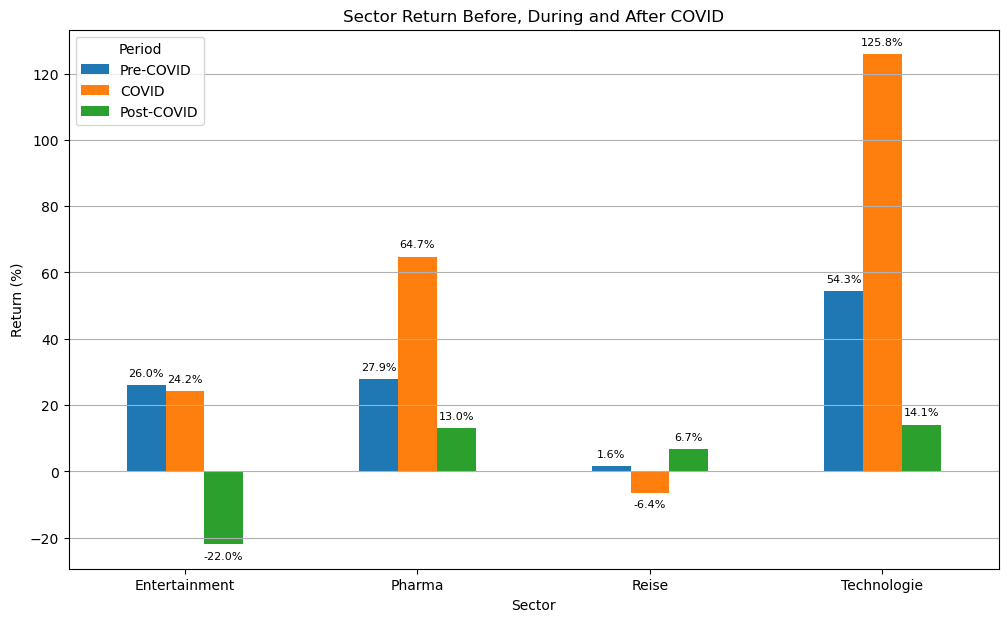

In [753]:
# Reshape the data and create a grouped bar chart
# to compare the average returns of each sector
# across the Pre-COVID, COVID and Post-COVID periods.
period_order = ["Pre-COVID", "COVID", "Post-COVID"]

period_pivot = sector_period_return.pivot(
    index="Sector",
    columns="Period",
    values="Return"
)

period_pivot = period_pivot[period_order]

ax = period_pivot.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Sector Return Before, During and After COVID")
plt.xlabel("Sector")
plt.ylabel("Return (%)")
plt.xticks(rotation=0)
plt.grid(axis="y")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=5,
        fontsize=8
    )
    
plt.show()

**Hinweis:** Das Diagramm zeigt deutliche Unterschiede zwischen den drei Zeiträumen. Während der COVID-Phase erzielte insbesondere der Technologiesektor die höchste durchschnittliche Rendite, gefolgt vom Pharmasektor. Der Reisesektor verzeichnete dagegen während der Pandemie eine negative Entwicklung. Nach der Pandemie gingen die Renditen in allen Sektoren deutlich zurück, was auf eine Normalisierung der Märkte hindeutet. Die Ergebnisse spiegeln Durchschnittswerte der Unternehmen innerhalb der jeweiligen Sektoren wider.

---

# Zusammenfassung der explorativen Datenanalyse (EDA)

Die explorative Datenanalyse liefert einen ersten Überblick über die Entwicklung der untersuchten Sektoren und Unternehmen im Zeitraum **2018–2023**. Der Technologiesektor erzielte insgesamt die höchste Performance und profitierte besonders während der COVID-19-Pandemie. Auch der Pharmasektor entwickelte sich überdurchschnittlich, während der Reisesektor die stärksten Einbußen verzeichnete. Auf Unternehmensebene gehörten **NVIDIA, Eli Lilly und Microsoft** zu den erfolgreichsten Werten, während **Carnival, Warner Bros. Discovery und Disney** die schwächste Performance aufwiesen.

> **Wichtig:**  
> Die Ergebnisse zeigen, dass die Entwicklung der Aktien **nicht ausschließlich durch die COVID-19-Pandemie** beeinflusst wurde. Auch die **Digitalisierung und der KI-Boom im Technologiesektor**, die **hohe Nachfrage nach Medikamenten und Gesundheitsprodukten**, die **Erholung der Reisebranche nach den Lockdowns** sowie **unternehmensspezifische Ereignisse** wie neue Produkte, Unternehmensstrategien oder Geschäftsergebnisse haben die Performance der einzelnen Unternehmen und Sektoren beeinflusst.

> **Fazit:**  
> Diese EDA stellt eine erste Analyse der Daten dar und dient als Grundlage für die nachfolgenden Analysen. Im nächsten Schritt werden dieselben Daten mithilfe von **SQL** und interaktiven **Power-BI-Dashboards** weiter untersucht, um Zusammenhänge und Entwicklungen übersichtlicher darzustellen und tiefere Einblicke in die Daten zu gewinnen.

---